# Which galaxies are consistently classified as mergers?

Inspect the completed pilot, or change the settings and run a new bundle.
The pilot contains Run 11 experiments 9/13/14. **Cross-run consistency still requires the other runs.**
See [MERGER_CONSENSUS.md](MERGER_CONSENSUS.md) for the analysis protocol and Delta commands.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
import merger_consensus as mc

# Run this notebook from the Hyrax-Research repository root.
BUNDLE = Path("results/merger_consensus_run11/full")
MANIFEST = Path("results/multi_latent_run11/inputs_manifest.json")

# Easy-to-change scientific and selection settings:
MERGER_TYPE = "major"   # major, minor, or mini
CUTOFF_GYR = 0.75
TOP_EXPERIMENTS = 3
N_SPLITS = 100
ALGORITHMS = ("logistic", "random_forest", "anchor")
config = mc.ConsensusConfig(
    target_column=MERGER_TYPE.title() + "_TimeSinceMerger",
    cutoff_gyr=CUTOFF_GYR,
    top_experiments=TOP_EXPERIMENTS,
    n_splits=N_SPLITS,
    algorithms=ALGORITHMS,
)


In [2]:
# To run changed settings, choose a NEW output directory and set RUN_ANALYSIS=True.
# Existing bundles are protected from overwriting.
RUN_ANALYSIS = False
if RUN_ANALYSIS:
    result = mc.run_analysis(MANIFEST, BUNDLE, config, shuffled_control=True)

record = json.loads((BUNDLE / "analysis_manifest.json").read_text())
assert record["status"] == "complete"
print("Saved settings (authoritative for the displayed results):")
display(record["config"])
print("Cross-run tested:", record["cross_run_tested"])
print("Coverage:", record["coverage"]["known_objects"], "known galaxies,",
      record["coverage"]["targets"], "catalog targets")
display(Markdown((BUNDLE / "meeting_brief.md").read_text()))


Saved settings (authoritative for the displayed results):
Cross-run tested: False
Coverage: 6079 known galaxies, 231 catalog targets


{'n_splits': 100,
 'seed': 42,
 'top_experiments': 3,
 'algorithms': ['logistic', 'random_forest', 'anchor'],
 'representations': ['latent', 'umap'],
 'neighbor_ranks': [3, 5, 7, 9],
 'target_column': 'Major_TimeSinceMerger',
 'cutoff_gyr': 0.75,
 'consensus_threshold': 0.5,
 'min_holdouts': 5,
 'cohort_mode': 'strict',
 'forest_trees': 128}

# Merger consensus

Target: `0 <= Major_TimeSinceMerger <= 0.75` Gyr. 6,079 known objects; 231 targets.

100 paired repetitions: 25% training, 25% validation, 50% held out. Select up to 3 experiments **per run, representation, and algorithm** using validation AP. Validation F1 fixes each classifier's threshold. No classifier is refitted on validation or test objects.

Votes are averaged over selected experiments, then equally over algorithms, then equally over runs. A galaxy's vote fraction averages only repetitions where it was held out. It is agreement, not a merger probability. Mean rank scores use each classifier's validation score CDF and also are not probabilities.

**Cross-run consistency has not been tested: this bundle contains only one run.**

## Latent

0 galaxies meet the cross-run stability rule; 0 scored galaxies have fewer than 5 holdouts.

| Object ID | Vote fraction | Lowest run vote | Unanimous splits | Holdouts | Catalog target |
|---|---:|---:|---:|---:|---|
| 72365847 | 0.794 | 0.794 | 0.234 | 47 | True |
| 72326206 | 0.785 | 0.785 | 0.102 | 49 | False |
| 72249573 | 0.766 | 0.766 | 0.196 | 56 | True |
| 72262513 | 0.754 | 0.754 | 0.170 | 47 | False |
| 72238159 | 0.745 | 0.745 | 0.114 | 44 | True |
| 72094171 | 0.742 | 0.742 | 0.045 | 44 | False |
| 72245976 | 0.742 | 0.742 | 0.132 | 53 | True |
| 72363914 | 0.733 | 0.733 | 0.093 | 54 | True |
| 72253363 | 0.729 | 0.729 | 0.091 | 55 | True |
| 72202087 | 0.722 | 0.722 | 0.107 | 56 | False |

Median held-out AP: 0.0585; purity: 11.8%; completeness: 14.8%.

## Umap

0 galaxies meet the cross-run stability rule; 0 scored galaxies have fewer than 5 holdouts.

| Object ID | Vote fraction | Lowest run vote | Unanimous splits | Holdouts | Catalog target |
|---|---:|---:|---:|---:|---|
| 72262513 | 0.931 | 0.931 | 0.617 | 47 | False |
| 72064210 | 0.896 | 0.896 | 0.429 | 49 | False |
| 72026681 | 0.895 | 0.895 | 0.500 | 52 | False |
| 72156034 | 0.886 | 0.886 | 0.476 | 42 | True |
| 72102474 | 0.880 | 0.880 | 0.373 | 51 | False |
| 72238159 | 0.879 | 0.879 | 0.364 | 44 | True |
| 72122536 | 0.875 | 0.875 | 0.518 | 56 | False |
| 72331189 | 0.875 | 0.875 | 0.417 | 48 | False |
| 72026680 | 0.873 | 0.873 | 0.357 | 56 | False |
| 72249573 | 0.869 | 0.869 | 0.357 | 56 | True |

Median held-out AP: 0.1018; purity: 15.8%; completeness: 19.1%.

## Reading the outputs

- `top_candidates_per_algorithm.csv`: top three galaxies for each algorithm and representation, averaged equally across runs.
- `consensus_candidates.csv`: complete consensus ranking with run coverage and stability flags.
- `run_candidates.csv`, `algorithm_candidates.csv`: the contributions behind that ranking.
- `experiment_selections.csv`: every validation rank, selected neighbor k, threshold, and top-experiment decision.
- `prediction_audit.npz`: exact IDs, partitions, selected model masks, thresholds, scores, and exact binary votes. Votes are -1 outside test sets. Stored float32 scores are approximate; exact votes are authoritative.

Stability requires at least two runs, at least 5 holdout appearances, and average vote >= 0.5 in **every** included run. This is distinct from unanimous classifier agreement, reported separately.

## Limits

Repeated holdouts overlap. Vote frequencies and split quantiles are descriptive, not independent probabilities or confidence intervals. Representations were previously trained, and existing UMAPs may have been fit using held-out objects without labels; this is a transductive, exploratory label-holdout analysis. It does not establish transfer to a new simulation or snapshot. Experiments preselected using earlier full-sample results retain selection optimism. Changing the target requires rerunning experiment selection and thresholds. Unknown labels are excluded and zero-holdout objects remain visible in cohort.csv. An empty selected set has purity reported as zero in this workflow.


In [3]:
consensus = pd.read_csv(BUNDLE / "consensus_candidates.csv", dtype={"object_id": str})
columns = ["object_id", "target", "vote_fraction", "minimum_run_vote_fraction",
           "unanimous_split_fraction", "n_holdouts", "n_runs", "stable_across_runs"]
for representation in record["config"]["representations"]:
    print(representation.upper(), "— top 10 galaxies")
    display(consensus.loc[consensus.representation.eq(representation), columns].head(10))


LATENT — top 10 galaxies
UMAP — top 10 galaxies


,object_id,target,vote_fraction,minimum_run_vote_fraction,unanimous_split_fraction,n_holdouts,n_runs,stable_across_runs
0,72365847,True,0.794326,0.794326,0.234043,47,1,False
1,72326206,False,0.784580,0.784580,0.102041,49,1,False
2,72249573,True,0.765873,0.765873,0.196429,56,1,False
3,72262513,False,0.754137,0.754137,0.170213,47,1,False
4,72238159,True,0.744949,0.744949,0.113636,44,1,False
5,72094171,False,0.742424,0.742424,0.045455,44,1,False
6,72245976,True,0.742138,0.742138,0.132075,53,1,False
7,72363914,True,0.732510,0.732510,0.092593,54,1,False
8,72253363,True,0.729293,0.729293,0.090909,55,1,False
9,72202087,False,0.722222,0.722222,0.107143,56,1,False


,object_id,target,vote_fraction,minimum_run_vote_fraction,unanimous_split_fraction,n_holdouts,n_runs,stable_across_runs
6079,72262513,False,0.931442,0.931442,0.617021,47,1,False
6080,72064210,False,0.895692,0.895692,0.428571,49,1,False
6081,72026681,False,0.895299,0.895299,0.500000,52,1,False
6082,72156034,True,0.886243,0.886243,0.476190,42,1,False
6083,72102474,False,0.880174,0.880174,0.372549,51,1,False
6084,72238159,True,0.878788,0.878788,0.363636,44,1,False
6085,72122536,False,0.875000,0.875000,0.517857,56,1,False
6086,72331189,False,0.875000,0.875000,0.416667,48,1,False
6087,72026680,False,0.873016,0.873016,0.357143,56,1,False
6088,72249573,True,0.869048,0.869048,0.357143,56,1,False


In [4]:
# Galaxies receiving substantial merger votes in EVERY included representation.
# These are averages over held-out appearances, not calibrated probabilities.
# This comparison does not establish cross-run consistency by itself.
representations = record["config"]["representations"]
space_votes = consensus.pivot(index="object_id", columns="representation", values="vote_fraction")
shared = space_votes.dropna().copy()
shared["minimum_space_vote"] = shared[representations].min(axis=1)
shared["mean_vote_across_spaces"] = shared[representations].mean(axis=1)
shared = shared.join(consensus.groupby("object_id")[["target", "n_holdouts"]].first())
shared = shared.sort_values(["minimum_space_vote", "mean_vote_across_spaces"], ascending=False)
print("Galaxies at or above the consensus threshold in every representation:",
      shared.minimum_space_vote.ge(record["config"]["consensus_threshold"]).sum())
display(shared.head(10))


Galaxies at or above the consensus threshold in every representation: 125


,latent,umap,minimum_space_vote,mean_vote_across_spaces,target,n_holdouts
object_id,,,,,,
72249573,0.765873,0.869048,0.765873,0.817460,True,56
72262513,0.754137,0.931442,0.754137,0.842790,False,47
72238159,0.744949,0.878788,0.744949,0.811869,True,44
72094171,0.742424,0.835859,0.742424,0.789141,False,44
72202087,0.722222,0.841270,0.722222,0.781746,False,56
72203772,0.720798,0.772080,0.720798,0.746439,True,39
72301381,0.719192,0.822222,0.719192,0.770707,False,55
72118307,0.717172,0.757576,0.717172,0.737374,True,44
72365847,0.794326,0.711584,0.711584,0.752955,True,47


In [5]:
print("Top three galaxies per classifier (equal average over runs):")
display(pd.read_csv(BUNDLE / "top_candidates_per_algorithm.csv", dtype={"object_id": str}))
print("Experiment selection frequency:")
display(pd.read_csv(BUNDLE / "experiment_selection_frequency.csv"))


Top three galaxies per classifier (equal average over runs):
Experiment selection frequency:


,representation,algorithm,object_id,target,n_runs,n_holdouts,vote_fraction,mean_rank_score,sufficient_holdouts
0,latent,random_forest,72262513,False,1,47,0.978723,0.984668,True
1,latent,random_forest,72231020,False,1,54,0.969136,0.991959,True
2,latent,random_forest,72308893,True,1,62,0.962366,0.985201,True
3,latent,anchor,72436590,False,1,56,0.946429,0.983079,True
4,latent,logistic,72365847,True,1,47,0.929078,0.964254,True
5,latent,anchor,72461742,False,1,47,0.921986,0.972504,True
6,latent,anchor,72437992,False,1,59,0.920904,0.975829,True
7,latent,logistic,72326206,False,1,49,0.884354,0.952305,True
8,latent,logistic,72249573,True,1,56,0.869048,0.948884,True
9,umap,logistic,72102474,False,1,51,0.973856,0.948009,True


,run,representation,algorithm,key,splits,times_selected,median_validation_ap,selection_fraction
0,11,latent,anchor,run11_expt13,100,100,0.040823,1.0
1,11,latent,anchor,run11_expt14,100,100,0.047659,1.0
2,11,latent,anchor,run11_expt9,100,100,0.047250,1.0
3,11,latent,logistic,run11_expt13,100,100,0.059025,1.0
4,11,latent,logistic,run11_expt14,100,100,0.058129,1.0
5,11,latent,logistic,run11_expt9,100,100,0.059982,1.0
6,11,latent,random_forest,run11_expt13,100,100,0.108071,1.0
7,11,latent,random_forest,run11_expt14,100,100,0.103152,1.0
8,11,latent,random_forest,run11_expt9,100,100,0.109320,1.0
9,11,umap,anchor,run11_expt13,100,100,0.097994,1.0


Shuffled-label control medians:


,level,representation,run,algorithm,average_precision,average_precision_p16,average_precision_p84,purity,completeness,f1
0,algorithm,latent,11,anchor,0.035801,0.032104,0.041550,0.038061,0.852174,0.067920
1,algorithm,latent,11,logistic,0.064032,0.057817,0.075524,0.084225,0.156522,0.107017
2,algorithm,latent,11,random_forest,0.104629,0.089895,0.122985,0.139846,0.182609,0.153692
3,algorithm,umap,11,anchor,0.088684,0.075388,0.105689,0.124127,0.200000,0.146873
4,algorithm,umap,11,logistic,0.095739,0.085543,0.108096,0.125172,0.260870,0.154074
5,algorithm,umap,11,random_forest,0.094644,0.078900,0.108229,0.141591,0.152174,0.148429
6,run,latent,11,all,0.058512,0.052487,0.067523,0.117879,0.147826,0.133132
7,run,umap,11,all,0.101793,0.089343,0.118561,0.158312,0.191304,0.170681
8,consensus,latent,all,all,0.058512,0.052487,0.067523,0.117879,0.147826,0.133132
9,consensus,umap,all,all,0.101793,0.089343,0.118561,0.158312,0.191304,0.170681


average_precision  ...        f1
level     representation algorithm                         ...          
algorithm latent         anchor                  0.039243  ...  0.065497
                         logistic                0.039693  ...  0.068458
                         random_forest           0.039100  ...  0.068655
          umap           anchor                  0.038898  ...  0.067744
                         logistic                0.038814  ...  0.069122
                         random_forest           0.039796  ...  0.069919
consensus latent         all                     0.039090  ...  0.065461
          umap           all                     0.039082  ...  0.067324
run       latent         all                     0.039090  ...  0.065461
          umap           all                     0.039082  ...  0.067324

[10 rows x 4 columns]

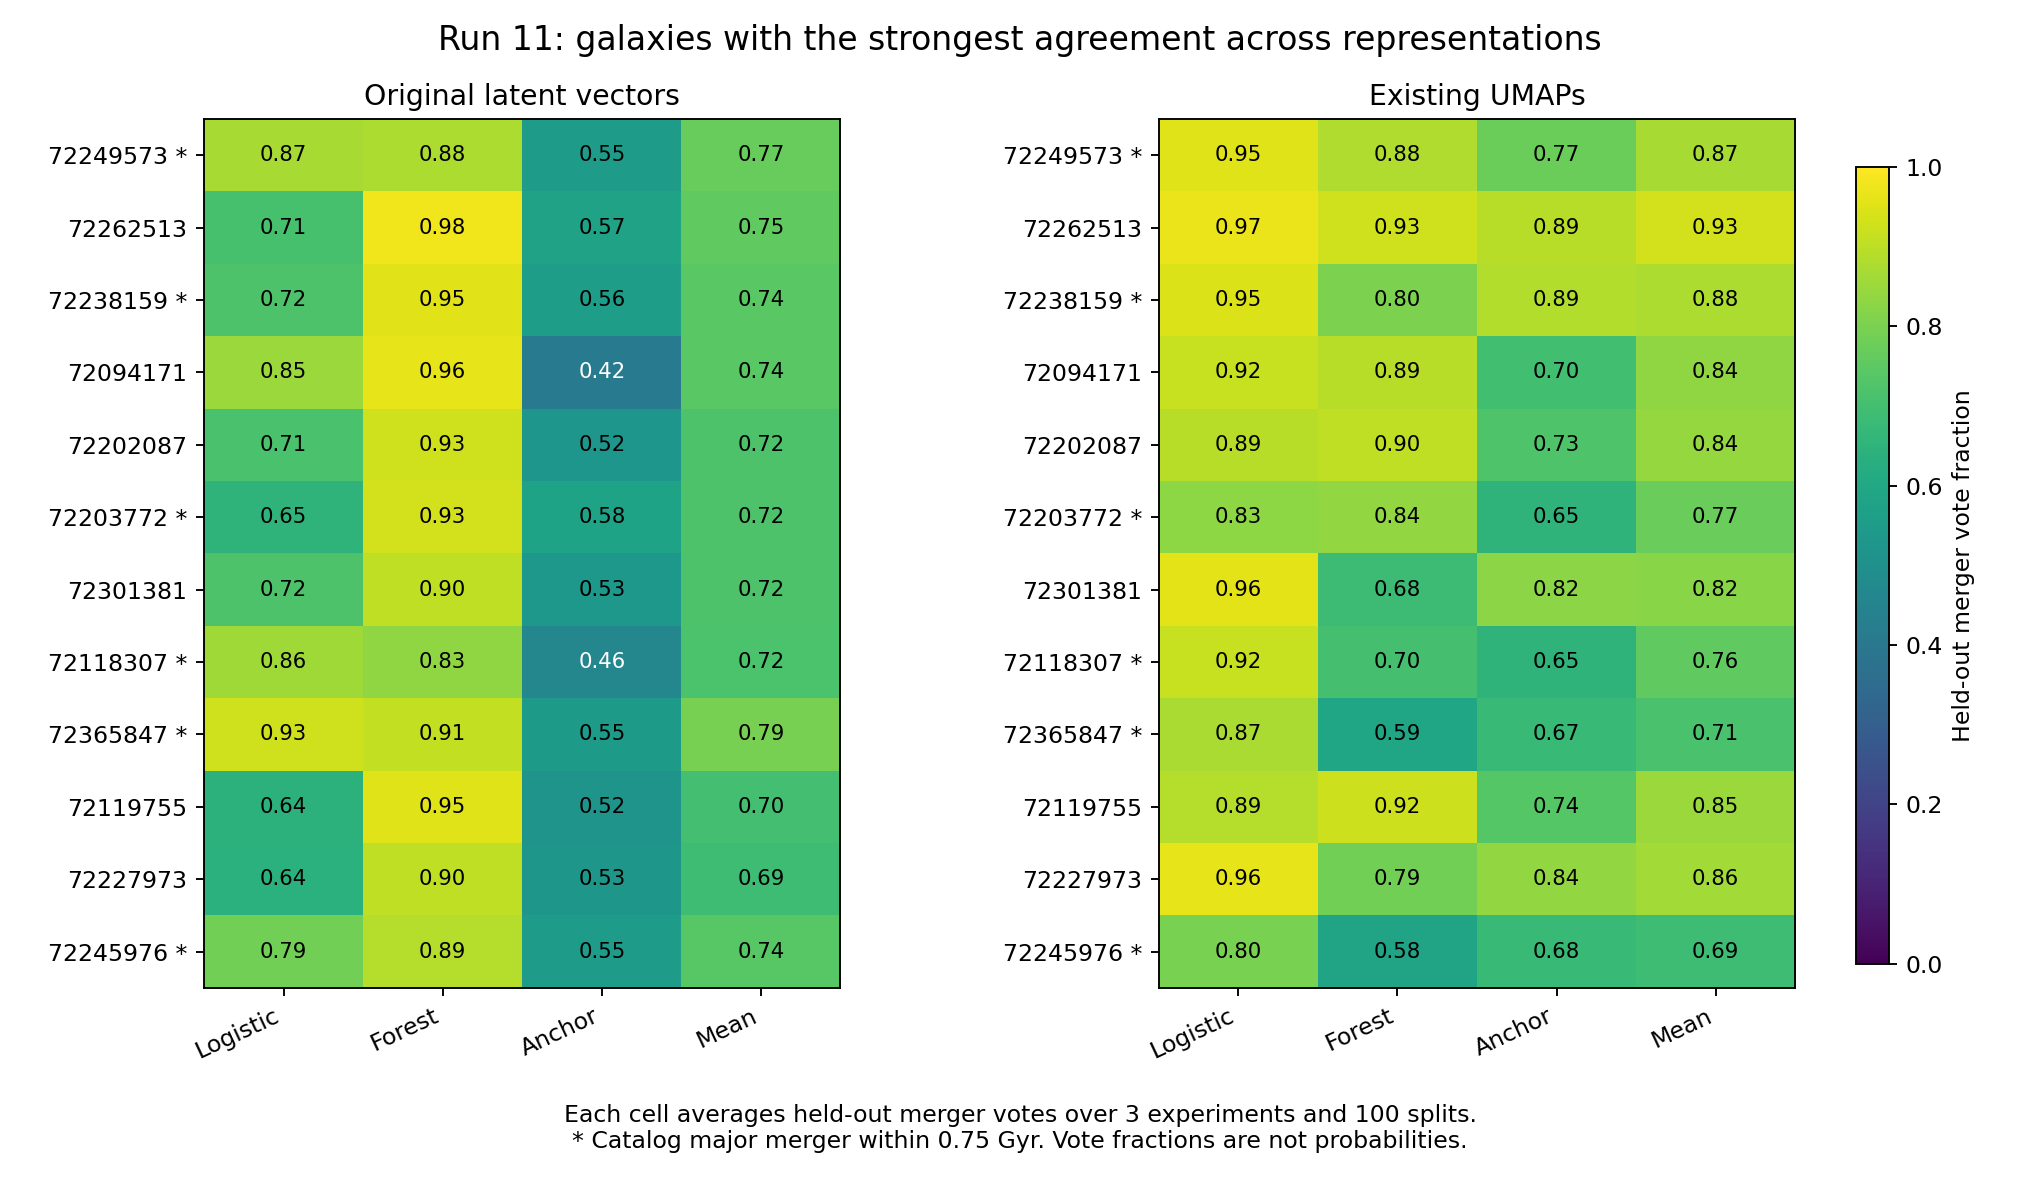

In [6]:
performance = pd.read_csv(BUNDLE / "performance_summary.csv", dtype={"run": str})
display(performance[["level", "representation", "run", "algorithm", "average_precision",
                     "average_precision_p16", "average_precision_p84", "purity", "completeness", "f1"]])
if (BUNDLE / "shuffled_split_metrics.csv").exists():
    shuffled = pd.read_csv(BUNDLE / "shuffled_split_metrics.csv")
    print("Shuffled-label control medians:")
    display(shuffled.groupby(["level", "representation", "algorithm"])[
        ["average_precision", "purity", "completeness", "f1"]].median())
figure = BUNDLE / "candidate_agreement.png"
if not figure.exists():
    figure = BUNDLE / "consensus_distribution.png"
if figure.exists():
    display(Image(filename=str(figure)))


In [7]:
if record["cross_run_tested"]:
    display(pd.read_csv(BUNDLE / "run_agreement.csv"))
    print("Galaxies meeting the cross-run stability rule:")
    display(consensus.loc[consensus.stable_across_runs, ["representation"] + columns])
else:
    print("One run only: no cross-run stability claim can be made.")


One run only: no cross-run stability claim can be made.


## Add the other runs

Authenticate to Delta and run `merger_consensus.py discover --profile delta --output results/merger_consensus_inputs.json` there.
Review the discovered experiments and failures, then run the analysis against that manifest in an approved compute environment.
Different historical UMAP parameters are allowed. IDs must align; use explicit intersection mode if needed.

Agreement is a candidate-prioritization measurement, not a merger probability. The notebook keeps latent and UMAP votes separate.
